# T13. Densidad de orígenes y destinos en H3 y concentración de la demanda

**Objetivo.** Ver dónde empiezan y acaban los viajes en una rejilla hexagonal H3 y cuántas celdas concentran la demanda.

**Valor para el proyecto.** Fija la resolución de la rejilla de candidatos a estación y el rango de número de estaciones que se barre en la fase 1. También comprueba si la demanda de la semana reservada cae en las mismas zonas que la del ajuste y busca extremos aislados para la limpieza.

Las cifras que fijan parámetros salen del periodo de ajuste (1–21/02) con los viajes elegibles; la semana reservada se describe para compararla. Los puntos aislados se buscan con todos los viajes del CSV.

In [1]:
import h3
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import patheffects
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FormatStrFormatter, FuncFormatter, MaxNLocator
from scipy.stats import spearmanr

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
RESOLUCIONES = CFG["exploracion"]["resoluciones_h3"]

PARAMETROS = {
    # Resolución de los mapas (punto de partida del plan).
    "res_mapas": 8,
    # Cuotas de extremos para las que se buscan las celdas necesarias (%).
    "cuotas_pct": [50, 80, 90, 95],
    # Porcentaje de celdas más usadas cuya demanda se mide (%).
    "celdas_top_pct": [10, 20],
    # Puntos aislados: celda con pocos extremos en todo el mes y lejos de cualquier
    # celda con demanda apreciable. Distancia entre centros de celda.
    "aislado_max_extremos": 2,
    "aislado_min_extremos_densa": 10,
    "aislado_dist_min_m": 1000,
}
TITULO_AJUSTE = "periodo de ajuste (1–21/02/2021)"

# Rampa secuencial de un solo tono (azul) y color para celdas sin dato.
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
CMAP_SECUENCIAL.set_bad("#e4e3df")
COLOR_TEXTO = "#3d3c39"
HALO = [patheffects.withStroke(linewidth=2.2, foreground="white")]
# Puntos de referencia para orientar los mapas (lat, lon aproximadas).
REFERENCIAS = {"Termini": (41.9009, 12.5019), "Coliseo": (41.8903, 12.4922), "San Pedro": (41.9022, 12.4536)}


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def celda(lat, lon, res):
    """Celda H3 de cada punto."""
    return pd.Series([h3.latlng_to_cell(a, b, res) for a, b in zip(lat, lon)], index=lat.index, dtype="string")


def centros(celdas):
    """Latitud y longitud del centro de cada celda."""
    coords = np.array([h3.cell_to_latlng(c) for c in celdas], dtype=float).reshape(-1, 2)
    return coords[:, 0], coords[:, 1]


def poligonos(celdas):
    """Contorno (lon, lat) de cada celda."""
    return [np.array(h3.cell_to_boundary(c))[:, ::-1] for c in celdas]


def contornos_web(celdas):
    """Contornos para la web: lista de [lon, lat] con 5 decimales por celda."""
    return [np.round(p, 5).tolist() for p in poligonos(celdas)]


def dibujar_celdas(eje, celdas, valores, cmap, norm, borde="white"):
    pc = PolyCollection(poligonos(celdas), array=np.asarray(valores, dtype=float), cmap=cmap,
                        norm=norm, edgecolors=borde, linewidths=0.3)
    eje.add_collection(pc)
    return pc


def extension(celdas, margen=0.004):
    puntos = np.vstack(poligonos(celdas))
    return (puntos[:, 0].min() - margen, puntos[:, 0].max() + margen,
            puntos[:, 1].min() - margen, puntos[:, 1].max() + margen)


def preparar_mapa(eje, ext, referencias=True, ejes=True, escala=True):
    """Límites, proporción local, puntos de referencia y barra de escala de 1 km."""
    lon0, lon1, lat0, lat1 = ext
    eje.set_xlim(lon0, lon1)
    eje.set_ylim(lat0, lat1)
    eje.set_aspect(1 / np.cos(np.radians((lat0 + lat1) / 2)))
    eje.grid(False)
    eje.tick_params(labelsize=8)
    eje.xaxis.set_major_locator(MaxNLocator(3))
    eje.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    eje.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    if ejes:
        eje.set_xlabel("Longitud (°)")
        eje.set_ylabel("Latitud (°)")
    else:
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in ("left", "bottom"):
            eje.spines[lado].set_visible(False)
    if referencias:
        for nombre, (lat, lon) in REFERENCIAS.items():
            if lon0 < lon < lon1 and lat0 < lat < lat1:
                eje.plot(lon, lat, marker="o", ms=3.5, mfc="white", mec="black", mew=0.8, zorder=5)
                eje.annotate(nombre, (lon, lat), xytext=(3, 3), textcoords="offset points",
                             fontsize=8, color="black", zorder=5, path_effects=HALO)
    if not escala:
        return
    # Barra de escala de 1 km en la esquina inferior izquierda.
    lat_b = lat0 + 0.05 * (lat1 - lat0)
    grados_km = 1000 / haversine_m(lat_b, 0.0, lat_b, 1.0)
    lon_b = lon0 + 0.06 * (lon1 - lon0)
    eje.plot([lon_b, lon_b + grados_km], [lat_b, lat_b], color="black", lw=2, solid_capstyle="butt")
    eje.annotate("1 km", (lon_b + grados_km / 2, lat_b), xytext=(0, 3), textcoords="offset points",
                 ha="center", fontsize=8, path_effects=HALO)


def barra_log(fig, pc, eje, etiqueta):
    """Barra de color con números enteros en lugar de potencias de 10."""
    barra = fig.colorbar(pc, ax=eje, shrink=0.8, pad=0.02)
    barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    barra.set_label(etiqueta)
    return barra


def tabla_indicadores(resumen):
    """Tabla indicador/valor que conserva los enteros como enteros en el CSV."""
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(list(resumen.values()), dtype=object)})


def conteo_celdas(viajes, res):
    """Orígenes, destinos y extremos por celda, ordenadas de más a menos extremos."""
    o = celda(viajes["latO"], viajes["lonO"], res).value_counts().rename("origenes")
    d = celda(viajes["latD"], viajes["lonD"], res).value_counts().rename("destinos")
    t = pd.concat([o, d], axis=1).fillna(0).astype("int64")
    t.index.name = "h3"
    t["extremos"] = t["origenes"] + t["destinos"]
    t = t.reset_index().sort_values(["extremos", "h3"], ascending=[False, True], ignore_index=True)
    t.insert(1, "res", res)
    t["lat"], t["lon"] = centros(t["h3"])
    return t


ajuste = cargar_viajes(periodo="ajuste")
reservada = cargar_viajes(periodo="reservada")
todos = cargar_viajes(solo_elegibles=False)
print(f"{len(ajuste)} viajes elegibles en el ajuste, {len(reservada)} en la reservada; {len(todos)} viajes en el CSV")

16710 viajes elegibles en el ajuste, 6582 en la reservada; 25186 viajes en el CSV


## 1. Densidad de orígenes y destinos

**Qué queremos ver.** Cuántos viajes empiezan y acaban en cada celda H3 de resolución 8 y 9, con el área y la arista media de cada resolución.

**Por qué importa.** La arista de la celda debe ser del orden del radio de acceso a una estación para que cada celda sea un candidato razonable. Los mapas dicen dónde buscar estaciones.

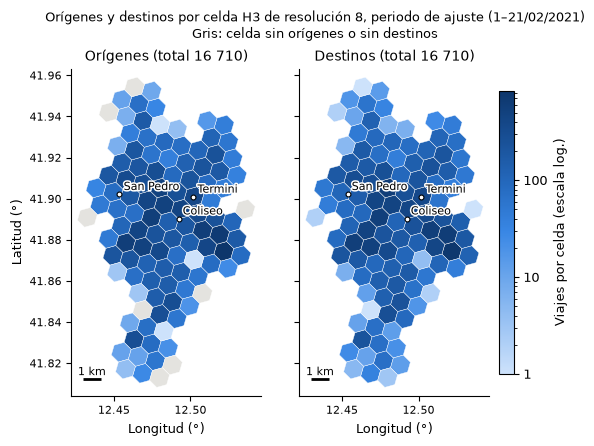

,res,area_media_km2,arista_media_m,viajes,origenes,destinos,celdas_con_demanda,extremos_por_celda_mediana,extremos_por_celda_max
0,8,0.7373,531.4,16710,16710,16710,111,190.0,1601
1,9,0.1053,200.8,16710,16710,16710,600,32.0,508


,h3,res,origenes,destinos,extremos,lat,lon
0,881e805089fffff,8,842,759,1601,41.874359,12.521776
1,881e8050c3fffff,8,663,610,1273,41.882557,12.519013
2,881e805003fffff,8,570,558,1128,41.878567,12.457688
3,881e8050c1fffff,8,570,540,1110,41.884627,12.507870
4,881e805019fffff,8,560,549,1109,41.890829,12.474440


In [2]:
conteos = {res: conteo_celdas(ajuste, res) for res in RESOLUCIONES}
densidad = pd.concat(conteos.values(), ignore_index=True)
densidad[["lat", "lon"]] = densidad[["lat", "lon"]].round(6)
guardar_tabla(densidad, "T13_densidad_celdas")

filas = []
for res, t in conteos.items():
    # Cuadre: cada viaje aporta un origen y un destino en cada resolución.
    assert t["origenes"].sum() == len(ajuste) and t["destinos"].sum() == len(ajuste), res
    filas.append({
        "res": res,
        "area_media_km2": round(h3.average_hexagon_area(res, unit="km^2"), 4),
        "arista_media_m": round(h3.average_hexagon_edge_length(res, unit="m"), 1),
        "viajes": len(ajuste),
        "origenes": int(t["origenes"].sum()),
        "destinos": int(t["destinos"].sum()),
        "celdas_con_demanda": len(t),
        "extremos_por_celda_mediana": float(t["extremos"].median()),
        "extremos_por_celda_max": int(t["extremos"].max()),
    })
resoluciones = pd.DataFrame(filas)
guardar_tabla(resoluciones, "T13_resoluciones_h3")

t = conteos[PARAMETROS["res_mapas"]]
ext = extension(t["h3"])
norm = LogNorm(vmin=1, vmax=pd.concat([t["origenes"], t["destinos"]]).max())
fig, ejes = plt.subplots(1, 2, figsize=(6.5, 4.6), sharey=True)
for eje, col, titulo in zip(ejes, ["origenes", "destinos"], ["Orígenes", "Destinos"]):
    pc = dibujar_celdas(eje, t["h3"], t[col].where(t[col] > 0, np.nan), CMAP_SECUENCIAL, norm)
    preparar_mapa(eje, ext)
    eje.set_title(f"{titulo} (total {t[col].sum():,})".replace(",", " "))
ejes[1].set_ylabel("")
barra_log(fig, pc, ejes, "Viajes por celda (escala log.)")
fig.suptitle(f"Orígenes y destinos por celda H3 de resolución {PARAMETROS['res_mapas']}, {TITULO_AJUSTE}\n"
             "Gris: celda sin orígenes o sin destinos", fontsize=9)
guardar_figura(fig, TEMA, f"T13_densidad_res{PARAMETROS['res_mapas']}")

exportar(FASE, "t13_densidad", {
    "res": PARAMETROS["res_mapas"], "referencias": REFERENCIAS,
    "celdas": [{"h3": c, "origenes": int(o), "destinos": int(d), "contorno": p}
               for c, o, d, p in zip(t["h3"], t["origenes"], t["destinos"], contornos_web(t["h3"]))],
})
display(resoluciones, t.head(5))

**Conclusiones.**

- En el ajuste hay demanda en 111 celdas de resolución 8 (0,74 km² y 531 m de arista media) y en 600 de resolución 9 (0,105 km² y 201 m). La mediana es de 190 extremos por celda en resolución 8 y de 32 en resolución 9.
- Orígenes y destinos ocupan las mismas celdas. La celda con más extremos (1 601) está al sureste del Coliseo; le siguen otras del este y del suroeste y la del centro, entre San Pedro y Termini.
- La **resolución 9** tiene una arista del orden del radio de acceso (200 m): es la rejilla para los candidatos. La resolución 8 se queda para mapas, saldos y matrices O-D.

## 2. Concentración de la demanda

**Qué queremos ver.** Cuántas celdas, ordenadas de más a menos usadas, reúnen el 50, 80, 90 y 95 % de los extremos y qué parte de la demanda cae en el 10 y el 20 % de celdas más usadas.

**Por qué importa.** El número de celdas que reúnen casi toda la demanda acota cuántas estaciones tiene sentido probar. Con el área de esas celdas y el radio de acceso sale un orden de magnitud del número de estaciones para cada radio del plan.

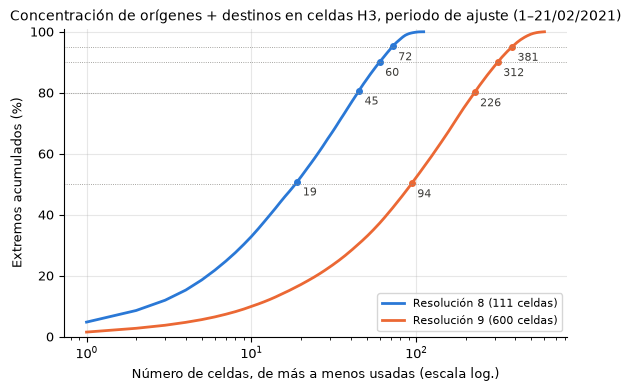

,res,celdas_con_demanda,extremos,celdas_50pct,area_50pct_km2,celdas_80pct,area_80pct_km2,celdas_90pct,area_90pct_km2,celdas_95pct,area_95pct_km2,pct_extremos_top10pct_celdas,pct_extremos_top20pct_celdas
0,8,111,33420,19,14.01,45,33.18,60,44.24,72,53.09,37.77,56.90
1,9,600,33420,94,9.90,226,23.81,312,32.86,381,40.13,37.24,58.12


radio_m,200,300,400
cuota_pct,,,
50,96,43,24
80,230,102,58
90,317,141,80
95,387,172,97


In [3]:
filas, curvas = [], {}
fig, eje = plt.subplots(figsize=(6.5, 4.0))
colores = {RESOLUCIONES[0]: "#2a78d6", RESOLUCIONES[1]: "#eb6834"}
for res, t in conteos.items():
    ext_celda = t["extremos"].to_numpy()  # ya ordenadas de más a menos
    total, n = int(ext_celda.sum()), len(ext_celda)
    acum = np.cumsum(ext_celda)
    fila = {"res": res, "celdas_con_demanda": n, "extremos": total}
    for p in PARAMETROS["cuotas_pct"]:
        k = int(np.argmax(acum * 100 >= p * total)) + 1
        fila[f"celdas_{p}pct"] = k
        fila[f"area_{p}pct_km2"] = round(k * h3.average_hexagon_area(res, unit="km^2"), 2)
    for q in PARAMETROS["celdas_top_pct"]:
        k = int(np.ceil(n * q / 100))
        fila[f"pct_extremos_top{q}pct_celdas"] = round(100 * acum[k - 1] / total, 2)
    filas.append(fila)
    curvas[f"res{res}"] = np.round(100 * acum / total, 3)

    x = np.arange(1, n + 1)
    eje.plot(x, 100 * acum / total, color=colores[res], lw=2, label=f"Resolución {res} ({n} celdas)")
    for p in PARAMETROS["cuotas_pct"]:
        k = fila[f"celdas_{p}pct"]
        eje.plot(k, 100 * acum[k - 1] / total, "o", ms=4, color=colores[res])
        eje.annotate(str(k), (k, 100 * acum[k - 1] / total), xytext=(4, -10), textcoords="offset points",
                     fontsize=8, color=COLOR_TEXTO)
for p in PARAMETROS["cuotas_pct"]:
    eje.axhline(p, color="#8a8984", lw=0.6, ls=":")
eje.set_xscale("log")
eje.set_xlabel("Número de celdas, de más a menos usadas (escala log.)")
eje.set_ylabel("Extremos acumulados (%)")
eje.set_ylim(0, 101)
eje.set_title(f"Concentración de orígenes + destinos en celdas H3, {TITULO_AJUSTE}")
eje.legend(loc="lower right")
guardar_figura(fig, TEMA, "T13_concentracion")
concentracion = pd.DataFrame(filas)
guardar_tabla(concentracion, "T13_concentracion")

# Orden de magnitud de estaciones para cada radio del plan: área de las celdas de
# resolución 9 que reúnen cada cuota, dividida entre el área que cubre una estación sin
# huecos en una malla hexagonal de círculos de radio R (hexágono inscrito, 3·√3/2·R²).
# No es una localización: solo acota el barrido.
res_fina = max(RESOLUCIONES)
acum = np.cumsum(conteos[res_fina]["extremos"].to_numpy())
filas = []
for radio in CFG["movilidad"]["radios_acceso_m"]:
    area_estacion = 3 * np.sqrt(3) / 2 * radio ** 2 / 1e6
    for p in PARAMETROS["cuotas_pct"]:
        k = int(np.argmax(acum * 100 >= p * acum[-1])) + 1
        area = k * h3.average_hexagon_area(res_fina, unit="km^2")
        filas.append({"radio_m": radio, "cuota_pct": p, "res": res_fina, "celdas": k,
                      "area_km2": round(area, 2), "area_por_estacion_km2": round(area_estacion, 4),
                      "estaciones_orden_magnitud": int(np.ceil(area / area_estacion))})
estaciones = pd.DataFrame(filas)
guardar_tabla(estaciones, "T13_estaciones_orden_magnitud")

exportar(FASE, "t13_concentracion", {"curvas": curvas, "tabla": concentracion, "estaciones": estaciones})
display(concentracion, estaciones.pivot(index="cuota_pct", columns="radio_m", values="estaciones_orden_magnitud"))

**Conclusiones.**

- La demanda está repartida: en resolución 8, 19 celdas reúnen el 50 % de los extremos, 45 el 80 % y 72 el 95 %; en resolución 9, 94, 226 y 381. El 20 % de celdas más usadas reúne el 56,9 % de los extremos en resolución 8 y el 58,1 % en resolución 9.
- Cubrir con círculos de radio R, en malla hexagonal, el área de las celdas de resolución 9 que reúnen del 80 al 95 % de los extremos pide **230–387 estaciones con 200 m, 102–172 con 300 m y 58–97 con 400 m**. Es el rango del barrido de k de la fase 1.
- Es una cuenta de área: supone demanda uniforme dentro de cada celda y no sustituye a la localización.

## 3. Puntos aislados

**Qué queremos ver.** Extremos cuya celda de resolución 8 tiene 2 o menos extremos en todo el mes y está a más de 1 km de la celda más cercana con 10 o más.

**Por qué importa.** Son candidatos a la marca `fuera_de_zona` de la limpieza: puntos donde nunca tendría sentido una estación.

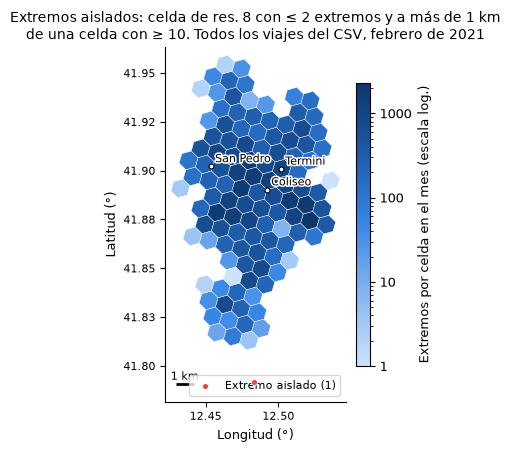

,res,viajes_mes,celdas_con_extremos,celdas_densas,celdas_poco_usadas,celdas_aisladas,extremos_aislados,viajes_afectados,viajes_afectados_elegibles,viajes_afectados_elegibles_ajuste
0,8,25186,115,103,6,1,1,1,0,0


,trip_id,extremo,h3,lat,lon,extremos_celda_mes,dist_celda_densa_m,elegible,periodo,motivo
0,14376,destino,881e80434bfffff,41.791932,12.482926,1,2821.0,False,ajuste,tt_largo


In [4]:
p = PARAMETROS
res = p["res_mapas"]
columnas = ["trip_id", "elegible", "periodo", "motivo"]
extremos = pd.concat([
    todos[columnas].assign(extremo="origen", lat=todos["latO"], lon=todos["lonO"]),
    todos[columnas].assign(extremo="destino", lat=todos["latD"], lon=todos["lonD"]),
], ignore_index=True)
extremos["h3"] = celda(extremos["lat"], extremos["lon"], res)
por_celda = extremos["h3"].value_counts().rename("extremos_celda_mes")
densas = por_celda[por_celda >= p["aislado_min_extremos_densa"]].index
pocas = por_celda[por_celda <= p["aislado_max_extremos"]].index
lat_d, lon_d = centros(densas)
lat_p, lon_p = centros(pocas)
dist = haversine_m(lat_p[:, None], lon_p[:, None], lat_d[None, :], lon_d[None, :]).min(axis=1)
dist = pd.Series(dist, index=pocas, name="dist_celda_densa_m")
aisladas = dist[dist > p["aislado_dist_min_m"]].index

sel = extremos[extremos["h3"].isin(aisladas)].join(por_celda, on="h3").join(dist.round(0), on="h3")
sel = sel.sort_values(["trip_id", "extremo"], ignore_index=True)
sel[["lat", "lon"]] = sel[["lat", "lon"]].round(6)
sel = sel[["trip_id", "extremo", "h3", "lat", "lon", "extremos_celda_mes", "dist_celda_densa_m",
           "elegible", "periodo", "motivo"]]
guardar_tabla(sel, "T13_puntos_aislados")

afectados = sel.drop_duplicates("trip_id")
aislados = pd.DataFrame([{
    "res": res,
    "viajes_mes": len(todos),
    "celdas_con_extremos": len(por_celda),
    "celdas_densas": len(densas),
    "celdas_poco_usadas": len(pocas),
    "celdas_aisladas": len(aisladas),
    "extremos_aislados": len(sel),
    "viajes_afectados": len(afectados),
    "viajes_afectados_elegibles": int(afectados["elegible"].sum()),
    "viajes_afectados_elegibles_ajuste": int((afectados["elegible"] & (afectados["periodo"] == "ajuste")).sum()),
}])
guardar_tabla(aislados, "T13_puntos_aislados_resumen")

t = por_celda.reset_index()
fig, eje = plt.subplots(figsize=(6.5, 4.6))
pc = dibujar_celdas(eje, t["h3"], t["extremos_celda_mes"], CMAP_SECUENCIAL,
                    LogNorm(vmin=1, vmax=t["extremos_celda_mes"].max()))
preparar_mapa(eje, extension(t["h3"]))
if len(sel):
    eje.scatter(sel["lon"], sel["lat"], s=18, facecolor="#e34948", edgecolor="white", lw=0.6, zorder=6,
                label=f"Extremo aislado ({len(sel)})")
    eje.legend(loc="lower right")
barra_log(fig, pc, eje, "Extremos por celda en el mes (escala log.)")
eje.set_title(f"Extremos aislados: celda de res. {res} con ≤ {p['aislado_max_extremos']} extremos y a más de "
              f"{p['aislado_dist_min_m'] / 1000:.0f} km\nde una celda con ≥ {p['aislado_min_extremos_densa']}. "
              "Todos los viajes del CSV, febrero de 2021")
guardar_figura(fig, TEMA, "T13_puntos_aislados")

exportar(FASE, "t13_aislados", {
    "resumen": aislados, "puntos": sel,
    "celdas": [{"h3": c, "extremos": int(n), "contorno": q}
               for c, n, q in zip(t["h3"], t["extremos_celda_mes"], contornos_web(t["h3"]))],
})
display(aislados, sel)

**Conclusiones.**

- De las 115 celdas con extremos en el mes, 103 tienen 10 o más y 6 tienen 2 o menos. Solo una de estas está a más de 1 km de una celda con demanda.
- Sale **un único extremo aislado**: el destino del viaje `trip_id` 14376, que ya no es elegible por `tt_largo`. No hace falta otra regla de limpieza por este motivo.

## 4. Estabilidad entre periodos

**Qué queremos ver.** Si las cuotas de demanda por celda del ajuste y de la semana reservada se parecen (correlación de Spearman) y qué parte de los extremos de la reservada cae en celdas que ya tenían demanda en el ajuste.

**Por qué importa.** Los candidatos se eligen con el ajuste y la red se valida con la reservada. Si la demanda cambiara de sitio, la validación no tendría sentido.

In [5]:
filas = []
for res in RESOLUCIONES:
    a = conteo_celdas(ajuste, res).set_index("h3")["extremos"]
    r = conteo_celdas(reservada, res).set_index("h3")["extremos"]
    union = a.index.union(r.index)
    cuota_a = a.reindex(union, fill_value=0) / a.sum()
    cuota_r = r.reindex(union, fill_value=0) / r.sum()
    filas.append({
        "res": res,
        "celdas_ajuste": len(a),
        "celdas_reservada": len(r),
        "celdas_union": len(union),
        "celdas_solo_reservada": int((~r.index.isin(a.index)).sum()),
        "spearman_cuotas": round(float(spearmanr(cuota_a, cuota_r).statistic), 4),
        "pct_extremos_reservada_en_celdas_ajuste": round(100 * r[r.index.isin(a.index)].sum() / r.sum(), 2),
    })
estabilidad = pd.DataFrame(filas)
guardar_tabla(estabilidad, "T13_estabilidad")
exportar(FASE, "t13_estabilidad", estabilidad)
display(estabilidad)

,res,celdas_ajuste,celdas_reservada,celdas_union,celdas_solo_reservada,spearman_cuotas,pct_extremos_reservada_en_celdas_ajuste
0,8,111,108,112,1,0.9775,99.98
1,9,600,563,614,14,0.9207,99.83


**Conclusiones.**

- La demanda es estable en el espacio: Spearman de 0,98 en resolución 8 y 0,92 en resolución 9.
- El 99,98 % (resolución 8) y el 99,83 % (resolución 9) de los extremos de la semana reservada caen en celdas que ya tenían demanda en el ajuste. Solo aparecen 1 y 14 celdas nuevas.
- Los candidatos del ajuste sirven para validar con la semana reservada.

## Decisiones

| Decisión | Valor |
|---|---|
| Rejilla de candidatos a estación | H3 de resolución 9 (arista de 201 m) |
| Rejilla de mapas, saldos y matrices O-D | H3 de resolución 8 |
| Rango de estaciones del barrido | 230–387 con 200 m, 102–172 con 300 m y 58–97 con 400 m |
| Marca `fuera_de_zona` | No hace falta: el único extremo aislado ya no es elegible |
| Validación con la semana reservada | Viable: la demanda no cambia de sitio |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.